# Model 3: CNN-LSTM for LOS/NLOS classification (fixed version)

This notebook trains the paper's **CNN-LSTM** (Section 3.3.4) on sequences of 50 frames and evaluates it on unseen environments, like the SVM and RF notebooks.

## Why this version

The first version used all **3328 values per frame** and an enlarged head. On the paper's split it reached 98.6%, but over all 60 paper-style splits only **84.6% ± 10.5%** (SVM 90.1%, RF 90.4%), with failures down to 48.5%. Its validation accuracy was **99.7%** while unseen environments gave about **85%**: it memorised the training environments. Those results are kept in `results_v1_full_resolution/`.

## The three fixes

| # | Fix | Before | Now |
|---|---|---|---|
| 1 | **Original architecture** (your model) | `padding="same"`, Dense(64), L2 = 0.0001, Dropout 0.5 | `padding="valid"`, **Dense(32), L2 = 0.001, Dropout 0.4** |
| 2 | **Compact input per frame** | 3328 values (64 antennas × 52 subcarriers) | **52 values**: amplitude per subcarrier, averaged over the 64 antennas (per-antenna normalised), close to the original 72 |
| 3 | **Epochs chosen on unseen environments** | early stopping on later windows of the *same* training clusters (validation 99.7%) | **inner folds hold out whole training clusters**; the epoch count with the lowest mean loss on those held-out clusters is used to train the final model on all training clusters |

Model size: about **219k parameters** (first version: about 850k).

Unchanged: windows of 50 frames with stride 10, Adam (lr 0.001), binary cross-entropy, batch 32, at most 50 epochs, z-score fitted on training clusters only, the test clusters and the 80-split evaluation.

## Code layout

The model and training code is in **`cnn_lstm_core.py`** next to this notebook:
- **Part A** imports it and runs the paper's split, with plots.
- **Part B** runs it as a separate process for each split. That keeps memory flat: training many models in one kernel previously crashed it.

**Steps (Part A: the paper's split)**
1. Setup and settings
2. Load the per-cluster features (compact input)
3. The paper's split and the inner folds
4. Build the model
5. Train: epoch selection on held-out clusters, then the final model
6. Selection and training curves
7. Classification metrics
8. Accuracy per test cluster
9. Confusion matrix
10. ROC and precision–recall curves
11. Probability distribution
12. Generalisation check and comparison (paper, SVM, RF, first CNN-LSTM)
13. Save the model and results

**Steps (Part B: all 80 splits)**

14. List all splits
15. Evaluation function (one process per split)
16. Run all splits (progress saved after every split)
17. Summary
18. Plots and saved summary
19. Comparison with SVM, RF and the first CNN-LSTM on the same splits

## Step 1: Setup and settings

All settings are in `CONFIG`. Only `input` and `noise_std` are meant to be changed for experiments:
- `input`: `"subcarrier"` (52 values, default), `"pca"` (`n_pca` principal components of the 3328 values, fitted on training clusters only) or `"full"` (3328, like the first version).
- `noise_std`: `0.0` = off (default). A value such as `0.1` adds Gaussian noise to the inputs during training (fix 4 in the discussion).

Kernel: **`dl_env`** (TensorFlow does not work in the Anaconda base environment on this Mac).

In [1]:
import os
import json
import sys
import importlib

import matplotlib.pyplot as plt
import numpy as np
import keras
from sklearn.metrics import (accuracy_score, average_precision_score, classification_report, confusion_matrix,
                             precision_recall_curve, roc_auc_score, roc_curve)

import cnn_lstm_core as core
importlib.reload(core)                      # picks up edits to cnn_lstm_core.py without restarting

print("Python", sys.version.split()[0], "| Keras", keras.__version__, "|", sys.executable)

DATA_DIR = os.path.abspath("../output_raw_full")
RESULTS_DIR = "results"
OTHER_RESULTS = {"SVM": "../SVM/results", "RF": "../RF/results",
                 "CNN-LSTM v1 (3328)": "results_v1_full_resolution"}   # for comparisons (optional)

CONFIG = dict(core.DEFAULT_CONFIG)
CONFIG.update({
    "input": "subcarrier",       # "subcarrier" (52) | "pca" | "full" (3328)
    "n_pca": 64,
    "conv_filters": [64, 128], "kernel_size": 3, "pool_size": 2, "padding": "valid",
    "lstm_units": [128, 64],
    "dense_units": 32, "l2": 1e-3, "dropout": 0.4,     # original model
    "noise_std": 0.0,
    "learning_rate": 1e-3, "batch_size": 32, "max_epochs": 50, "inner_patience": 10,
    "window": 50, "stride": 10, "seed": 42,
    "data_dir": DATA_DIR,
})
for k, v in CONFIG.items():
    print(f"  {k:15s} {v}")

CLASS_NAMES = ["NLOS (0)", "LOS (1)"]

# chart colours (reference palette)
COLOR_LOS = "#2a78d6"      # also "training"
COLOR_NLOS = "#eb6834"
COLOR_VAL = "#1baf7a"      # held-out / validation
INK = "#0b0b0b"
INK_2 = "#52514e"
GRID = "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": INK_2, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11, "lines.linewidth": 2,
})
os.makedirs(RESULTS_DIR, exist_ok=True)

Python 3.11.15 | Keras 3.14.1 | /opt/anaconda3/envs/dl_env/bin/python
  input           subcarrier
  n_pca           64
  conv_filters    [64, 128]
  kernel_size     3
  pool_size       2
  padding         valid
  lstm_units      [128, 64]
  dense_units     32
  dropout         0.4
  l2              0.001
  noise_std       0.0
  learning_rate   0.001
  batch_size      32
  max_epochs      50
  inner_patience  10
  window          50
  stride          10
  seed            42
  data_dir        /Users/gyanendramohanpatel/Desktop/Mrudula Paper/preprocessing_v2/output_raw_full


## Step 2: Load the per-cluster features (compact input)

The per-cluster features in `../output_raw_full/clusters/` (per-antenna normalised, before the z-score) are reduced to the chosen input. With `input = "subcarrier"`, each frame's 64 × 52 amplitudes are averaged over the antennas, giving **52 values per frame**. That is about 11 MB in memory for all 9 clusters.

In [2]:
LOS_CLUSTERS = ["LOS_cluster1", "LOS_cluster2", "LOS_cluster3", "LOS_cluster4"]
NLOS_CLUSTERS = ["NLOS_cluster1", "NLOS_cluster2", "NLOS_cluster3", "NLOS_cluster4", "NLOS_cluster5"]
ALL_CLUSTERS = LOS_CLUSTERS + NLOS_CLUSTERS

frames, labels = core.load_cluster_frames(DATA_DIR, ALL_CLUSTERS, CONFIG["input"])
W, S = CONFIG["window"], CONFIG["stride"]
for c in ALL_CLUSTERS:
    n_win = (len(frames[c]) - W) // S + 1
    print(f"{c:14s} label={labels[c]}  frames={frames[c].shape}  windows={n_win}")

LOS_cluster1   label=1  frames=(7939, 52)  windows=789
LOS_cluster2   label=1  frames=(7958, 52)  windows=791
LOS_cluster3   label=1  frames=(7911, 52)  windows=787
LOS_cluster4   label=1  frames=(7900, 52)  windows=786
NLOS_cluster1  label=0  frames=(5880, 52)  windows=584
NLOS_cluster2  label=0  frames=(3853, 52)  windows=381
NLOS_cluster3  label=0  frames=(3857, 52)  windows=381
NLOS_cluster4  label=0  frames=(3856, 52)  windows=381
NLOS_cluster5  label=0  frames=(3862, 52)  windows=382


## Step 3: The paper's split and the inner folds

| Set | Clusters |
|---|---|
| Train | LOS 1, LOS 2, NLOS 1, NLOS 2, NLOS 3 |
| Test (unseen) | LOS 3, LOS 4, NLOS 4, NLOS 5 |

**Inner folds (fix 3):** to choose the number of epochs without touching the test clusters, the training clusters are split again. Each inner fold holds out **one LOS and one NLOS training cluster**, and every training cluster is held out at least once. A model trained on the rest is scored on the held-out clusters after every epoch. These are environments that fold's model hasn't seen, the same situation as the real test.

In [3]:
PAPER_SPLIT = {"name": "test=LOS3+LOS4+NLOS4+NLOS5",
               "train": ["LOS_cluster1", "LOS_cluster2", "NLOS_cluster1", "NLOS_cluster2", "NLOS_cluster3"],
               "test": ["LOS_cluster3", "LOS_cluster4", "NLOS_cluster4", "NLOS_cluster5"]}

for k, fold in enumerate(core.inner_folds(PAPER_SPLIT["train"]), 1):
    print(f"inner fold {k}: train on {fold['train']}\n              hold out {fold['val']}")

inner fold 1: train on ['LOS_cluster2', 'NLOS_cluster2', 'NLOS_cluster3']
              hold out ['LOS_cluster1', 'NLOS_cluster1']
inner fold 2: train on ['LOS_cluster1', 'NLOS_cluster1', 'NLOS_cluster3']
              hold out ['LOS_cluster2', 'NLOS_cluster2']
inner fold 3: train on ['LOS_cluster2', 'NLOS_cluster1', 'NLOS_cluster2']
              hold out ['LOS_cluster1', 'NLOS_cluster3']


## Step 4: Build the model

Your original architecture, with 52 inputs per time step:

| Block | Layers | Sequence length |
|---|---|---|
| CNN | Conv1D(64, 3, valid) → BN → MaxPool(2) → Conv1D(128, 3, valid) → BN → MaxPool(2) | 50 → 48 → 24 → 22 → 11 |
| Temporal | LSTM(128, all steps) → LSTM(64, last step) | 11 → 1 |
| Head | Dense(32, ReLU, L2 = 0.001) → Dropout(0.4) → Dense(1, sigmoid) | P(LOS) |

In [4]:
n_features = frames[ALL_CLUSTERS[0]].shape[1] if CONFIG["input"] != "pca" else CONFIG["n_pca"]
core.build_model(CONFIG, W, n_features).summary()

Model: "cnn_lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 50, 52)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 48, 64)         │        10,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 24, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 22, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 22, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 11, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 11, 128)        │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 218,625 (854.00 KB)

 Trainable params: 218,241 (852.50 KB)

 Non-trainable params: 384 (1.50 KB)

## Step 5: Train

1. **Epoch selection:** each inner fold is trained (up to 50 epochs, stopping 10 epochs after its best held-out loss) and its held-out loss is recorded every epoch. The epoch count with the **lowest average held-out loss** is selected.
2. **Final model:** a new model is trained on **all** training clusters for exactly that many epochs.
3. **Test:** the final model predicts the unseen test clusters.

This takes about a minute.

In [5]:
result, details = core.train_and_evaluate(CONFIG, frames, labels, PAPER_SPLIT, verbose=True)
model = details["model"]
p_los, y_test, y_pred, g_test = details["p_los"], details["y_true"], details["y_pred"], details["groups"]
sel = details["selection"]

print(f"\nselected epochs     : {result['selected_epochs']}")
print(f"epoch selection time: {result['select_seconds']:.0f} s, final training: {result['fit_seconds']:.0f} s")
print(f"training windows    : {result['n_train_windows']}, test windows: {result['n_test_windows']}")

  inner fold 1: held out ['LOS_cluster1', 'NLOS_cluster1']  best val_loss 0.0073 at epoch 20, val_acc there 0.9985  (30 epochs run)
  inner fold 2: held out ['LOS_cluster2', 'NLOS_cluster2']  best val_loss 0.0416 at epoch 2, val_acc there 0.9983  (12 epochs run)
  inner fold 3: held out ['LOS_cluster1', 'NLOS_cluster3']  best val_loss 0.0418 at epoch 6, val_acc there 0.9889  (16 epochs run)

selected epochs     : 6
epoch selection time: 41 s, final training: 7 s
training windows    : 2926, test windows: 2336


## Step 6: Selection and training curves

- **Left:** the loss on the held-out training clusters for each inner fold (thin lines) and their average (thick). The dashed line is the selected epoch count. If the held-out loss rises while training continues, the model is starting to memorise the training environments.
- **Right:** the training loss and accuracy of the final model.

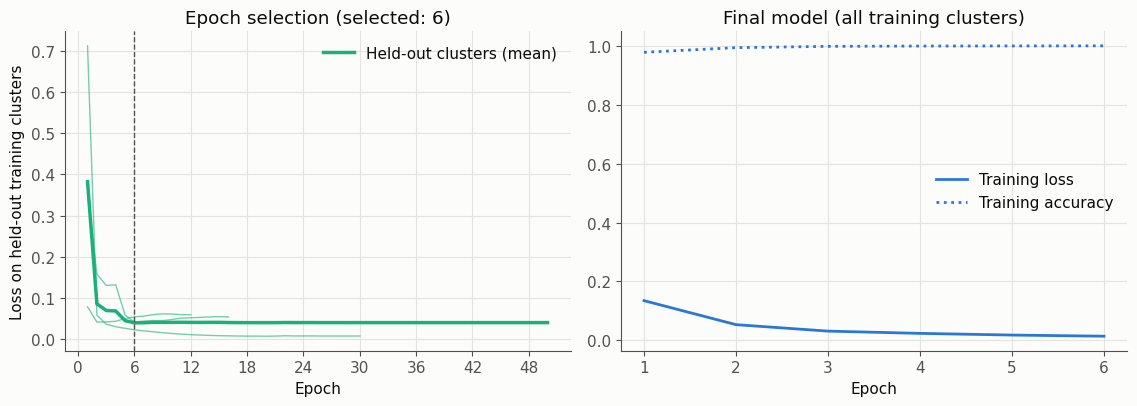

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
E = CONFIG["max_epochs"]
ax = axes[0]
for cv in sel["curves"]:
    n = cv["epochs_run"]
    ax.plot(np.arange(1, n + 1), cv["val_loss"][:n], color=COLOR_VAL, linewidth=1, alpha=0.6)
mean_loss = np.array(sel["mean_val_loss"])
ax.plot(np.arange(1, E + 1), mean_loss, color=COLOR_VAL, linewidth=2.5, label="Held-out clusters (mean)")
ax.axvline(result["selected_epochs"], color=INK_2, linestyle="--", linewidth=1)
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss on held-out training clusters")
ax.set_title(f"Epoch selection (selected: {result['selected_epochs']})")
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.legend(frameon=False)

ax = axes[1]
h = details["history"]
ep = np.arange(1, len(h["loss"]) + 1)
ax.plot(ep, h["loss"], color=COLOR_LOS, label="Training loss")
ax.plot(ep, h["accuracy"], color=COLOR_LOS, linestyle=":", label="Training accuracy")
ax.set_xlabel("Epoch")
ax.set_title("Final model (all training clusters)")
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "training_curves.png"), dpi=150)
plt.show()

## Step 7: Classification metrics

In [7]:
acc = accuracy_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, p_los)
pr_auc = average_precision_score(y_test, p_los)
print(f"Accuracy : {acc:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")
print(f"PR-AUC   : {pr_auc:.4f}  (average precision, LOS as positive class)")
print()
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4))
report = classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4, output_dict=True)

Accuracy : 1.0000
ROC-AUC  : 1.0000
PR-AUC   : 1.0000  (average precision, LOS as positive class)

              precision    recall  f1-score   support

    NLOS (0)     1.0000    1.0000    1.0000       763
     LOS (1)     1.0000    1.0000    1.0000      1573

    accuracy                         1.0000      2336
   macro avg     1.0000    1.0000    1.0000      2336
weighted avg     1.0000    1.0000    1.0000      2336



## Step 8: Accuracy per test cluster

In [8]:
per_cluster = {}
print(f"{'cluster':14s} {'label':>5s} {'windows':>7s} {'accuracy':>9s} {'mean P(LOS)':>12s}")
for c in PAPER_SPLIT["test"]:
    m = g_test == c
    per_cluster[c] = {"label": int(y_test[m][0]), "windows": int(m.sum()),
                      "accuracy": float(accuracy_score(y_test[m], y_pred[m])), "mean_p_los": float(p_los[m].mean())}
    r = per_cluster[c]
    print(f"{c:14s} {r['label']:5d} {r['windows']:7d} {r['accuracy']:9.4f} {r['mean_p_los']:12.4f}")

cluster        label windows  accuracy  mean P(LOS)
LOS_cluster3       1     787    1.0000       0.9999
LOS_cluster4       1     786    1.0000       0.9999
NLOS_cluster4      0     381    1.0000       0.0001
NLOS_cluster5      0     382    1.0000       0.0001


## Step 9: Confusion matrix

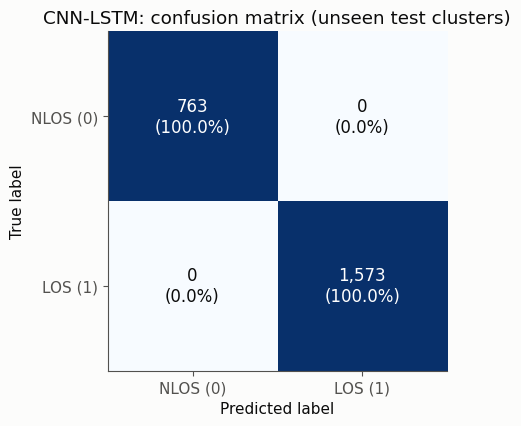

[[ 763    0]
 [   0 1573]]


In [9]:
cm = confusion_matrix(y_test, y_pred)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
fig, ax = plt.subplots(figsize=(5.2, 4.4))
ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=100)
ax.grid(False)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}\n({cm_pct[i, j]:.1f}%)", ha="center", va="center",
                color="white" if cm_pct[i, j] > 60 else INK, fontsize=12)
ax.set_xticks([0, 1], CLASS_NAMES)
ax.set_yticks([0, 1], CLASS_NAMES)
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title("CNN-LSTM: confusion matrix (unseen test clusters)")
fig.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "confusion_matrix.png"), dpi=150)
plt.show()
print(cm)

## Step 10: ROC and precision–recall curves

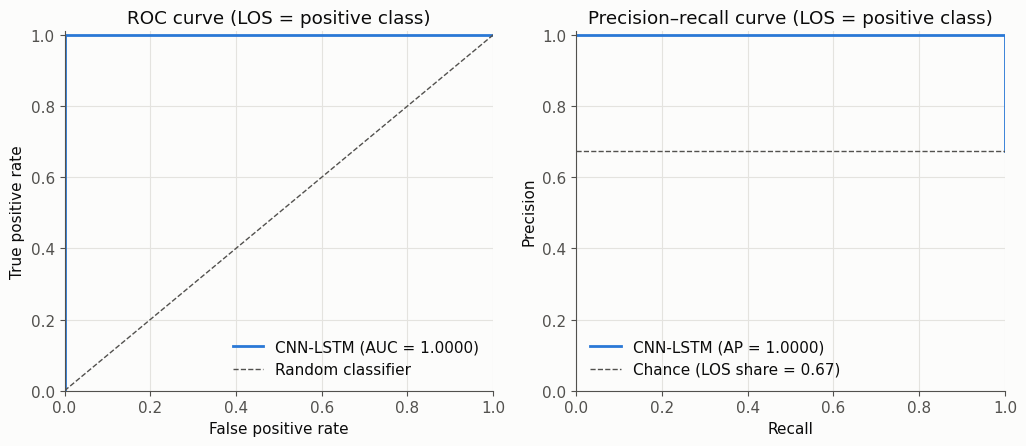

In [10]:
fpr, tpr, _ = roc_curve(y_test, p_los)
prec, rec, _ = precision_recall_curve(y_test, p_los)
fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.6))
axes[0].plot(fpr, tpr, color=COLOR_LOS, label=f"CNN-LSTM (AUC = {roc_auc:.4f})")
axes[0].plot([0, 1], [0, 1], color=INK_2, linestyle="--", linewidth=1, label="Random classifier")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curve (LOS = positive class)")
axes[0].legend(loc="lower right", frameon=False)
axes[1].plot(rec, prec, color=COLOR_LOS, label=f"CNN-LSTM (AP = {pr_auc:.4f})")
axes[1].axhline(y_test.mean(), color=INK_2, linestyle="--", linewidth=1, label=f"Chance (LOS share = {y_test.mean():.2f})")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision–recall curve (LOS = positive class)")
axes[1].legend(loc="lower left", frameon=False)
for ax in axes:
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.01)
fig.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "roc_pr_curves.png"), dpi=150)
plt.show()

## Step 11: Probability distribution

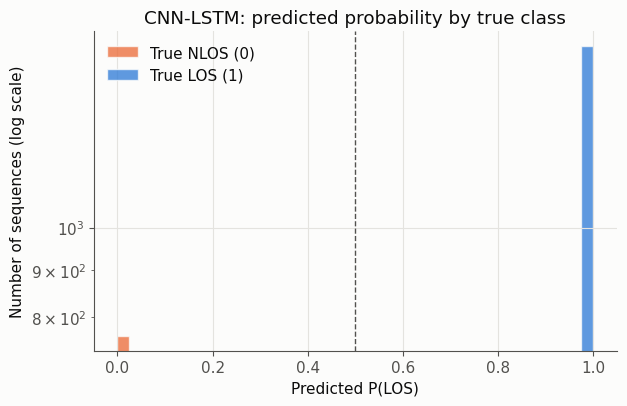

In [11]:
bins = np.linspace(0, 1, 41)
fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.hist(p_los[y_test == 0], bins=bins, color=COLOR_NLOS, alpha=0.75, label="True NLOS (0)", edgecolor="#fcfcfb", linewidth=1)
ax.hist(p_los[y_test == 1], bins=bins, color=COLOR_LOS, alpha=0.75, label="True LOS (1)", edgecolor="#fcfcfb", linewidth=1)
ax.axvline(0.5, color=INK_2, linestyle="--", linewidth=1)
ax.set_yscale("log")
ax.set_xlabel("Predicted P(LOS)")
ax.set_ylabel("Number of sequences (log scale)")
ax.set_title("CNN-LSTM: predicted probability by true class")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "probability_distribution.png"), dpi=150)
plt.show()

## Step 12: Generalisation check and comparison

| Accuracy | Data | Meaning |
|---|---|---|
| Training | all training windows | fit to known data |
| Inner held-out (at the selected epoch) | held-out **training clusters** | estimate for **unseen** environments, computed without the test clusters |
| Test | the unseen test clusters | the real result |

If the inner held-out accuracy and the test accuracy are close, the model's generalisation is predictable from the training data alone. In the first version, validation said 99.7% and the test said about 85%.

The comparison table lists the paper's CNN-LSTM (Table 5 / Fig. 4), this project's SVM and RF (single frames) and the first CNN-LSTM (3328 inputs), if their results exist.

In [12]:
print(f"training accuracy          : {result['train_accuracy']:.4f}")
print(f"inner held-out accuracy    : {result['inner_cv_accuracy']:.4f}   (unseen training clusters)")
print(f"test accuracy              : {acc:.4f}   (unseen test clusters)\n")

paper_cm = np.array([[803, 0], [210, 1403]])
paper = {"accuracy": 0.91, "roc_auc": 1.00}
for k, cls in enumerate(CLASS_NAMES):
    tp, fp, fn = paper_cm[k, k], paper_cm[1 - k, k], paper_cm[k, 1 - k]
    p_, r_ = tp / (tp + fp), tp / (tp + fn)
    paper[cls] = {"precision": p_, "recall": r_, "f1-score": 2 * p_ * r_ / (p_ + r_), "support": int(paper_cm[k].sum())}

others = {}
for name, d in OTHER_RESULTS.items():
    path = os.path.join(d, "metrics.json")
    if os.path.exists(path):
        others[name] = json.load(open(path))

cols = ["paper CNN-LSTM"] + list(others) + ["this run"]
def val_of(src, key, cls=None):
    if src == "paper CNN-LSTM":
        return paper[key] if cls is None else paper[cls][key]
    if src == "this run":
        return {"accuracy": acc, "roc_auc": roc_auc}[key] if cls is None else report[cls][key]
    m = others[src]
    return m[key] if cls is None else m["classification_report"][cls][key]

rows = [("Accuracy", "accuracy", None), ("ROC-AUC", "roc_auc", None)]
rows += [(f"{cls} {k}", k, cls) for cls in CLASS_NAMES for k in ["precision", "recall", "f1-score", "support"]]
print(f"{'metric':22s}" + "".join(f"{c:>20s}" for c in cols))
for label, key, cls in rows:
    fmt = "{:20.0f}" if key == "support" else "{:20.4f}"
    print(f"{label:22s}" + "".join(fmt.format(val_of(c, key, cls)) for c in cols))
print("\n(support = frames for SVM/RF, windows for the CNN-LSTMs)")

training accuracy          : 1.0000
inner held-out accuracy    : 0.9933   (unseen training clusters)
test accuracy              : 1.0000   (unseen test clusters)

metric                      paper CNN-LSTM                 SVM                  RF  CNN-LSTM v1 (3328)            this run
Accuracy                            0.9100              0.9938              0.9986              0.9859              1.0000
ROC-AUC                             1.0000              0.9998              1.0000              0.9993              1.0000
NLOS (0) precision                  0.7927              0.9945              0.9959              0.9893              1.0000
NLOS (0) recall                     1.0000              0.9865              1.0000              0.9672              1.0000
NLOS (0) f1-score                   0.8844              0.9905              0.9979              0.9781              1.0000
NLOS (0) support                       803                7718                7718                 

## Step 13: Save the model and results

In [13]:
model.save(os.path.join(RESULTS_DIR, "cnn_lstm_model.keras"))
np.savez(os.path.join(RESULTS_DIR, "predictions.npz"), y_true=y_test, y_pred=y_pred, p_los=p_los, groups=g_test)
metrics = {
    "model": "CNN-LSTM (fixed: original architecture, compact input, epochs chosen on held-out clusters)",
    "config": CONFIG, "n_parameters": int(model.count_params()),
    "accuracy": acc, "roc_auc": roc_auc, "pr_auc": pr_auc,
    "train_accuracy": result["train_accuracy"], "inner_cv_accuracy": result["inner_cv_accuracy"],
    "selected_epochs": result["selected_epochs"],
    "classification_report": report, "confusion_matrix": cm.tolist(), "per_cluster": per_cluster,
    "selection": sel, "history": details["history"],
    "select_seconds": result["select_seconds"], "fit_seconds": result["fit_seconds"],
}
with open(os.path.join(RESULTS_DIR, "metrics.json"), "w") as f:
    json.dump(metrics, f, indent=2)
for fn in sorted(os.listdir(RESULTS_DIR)):
    path = os.path.join(RESULTS_DIR, fn)
    if os.path.isfile(path):
        print(f"{fn:28s} {os.path.getsize(path) / 1e6:7.2f} MB")

cnn_lstm_model.keras            2.69 MB
confusion_matrix.png            0.04 MB
metrics.json                    0.02 MB
predictions.npz                 0.14 MB
probability_distribution.png    0.04 MB
roc_pr_curves.png               0.07 MB
training_curves.png             0.08 MB


---
# Part B: evaluation on all splits

## Step 14: List all splits

| Protocol | Test set per split | Train set per split | Number of splits |
|---|---|---|---|
| `lopo`: leave-one-pair-out | 1 LOS + 1 NLOS cluster | the other 7 clusters | 4 × 5 = **20** |
| `paper_style`: all paper-like splits | 2 LOS + 2 NLOS clusters | the other 2 LOS + 3 NLOS | C(4,2) × C(5,2) = 6 × 10 = **60** |

For every split, the full procedure of Step 5 is repeated: inner folds on that split's training clusters, the epoch count chosen on them, the final model trained on all training clusters, and the test clusters predicted. Each split runs in **its own process** (`cnn_lstm_core.py`), so memory stays flat.

**Runtime** (this Mac's CPU): roughly 40–90 s per split, so about **20–30 min for `lopo`** and **45–90 min for `paper_style`**. Progress is saved after each split. If the run stops, run Step 16 again and it continues where it left off.

**To run only Part B:** run Steps 1 and 2, then Steps 14–19.

In [14]:
import itertools

PAPER_TEST = ["LOS_cluster3", "LOS_cluster4", "NLOS_cluster4", "NLOS_cluster5"]
PROTOCOLS = ["lopo", "paper_style"]   # run both; remove one to save time
short = lambda c: c.replace("_cluster", "")

def make_splits(protocol):
    if protocol == "lopo":
        tests = [[l, n] for l in LOS_CLUSTERS for n in NLOS_CLUSTERS]
    elif protocol == "paper_style":
        tests = [list(ls) + list(ns) for ls in itertools.combinations(LOS_CLUSTERS, 2)
                 for ns in itertools.combinations(NLOS_CLUSTERS, 2)]
    else:
        raise ValueError(protocol)
    return [{"name": "test=" + "+".join(short(c) for c in test),
             "train": [c for c in ALL_CLUSTERS if c not in test], "test": test} for test in tests]

SPLITS = {p: make_splits(p) for p in PROTOCOLS}
for p, splits in SPLITS.items():
    print(f"{p}: {len(splits)} splits")
    for i, sp in enumerate(splits, 1):
        mark = "   <- paper split" if sorted(sp["test"]) == sorted(PAPER_TEST) else ""
        print(f"  {i:2d}. train={'+'.join(short(c) for c in sp['train']):38s} {sp['name']}{mark}")

lopo: 20 splits
   1. train=LOS2+LOS3+LOS4+NLOS2+NLOS3+NLOS4+NLOS5 test=LOS1+NLOS1
   2. train=LOS2+LOS3+LOS4+NLOS1+NLOS3+NLOS4+NLOS5 test=LOS1+NLOS2
   3. train=LOS2+LOS3+LOS4+NLOS1+NLOS2+NLOS4+NLOS5 test=LOS1+NLOS3
   4. train=LOS2+LOS3+LOS4+NLOS1+NLOS2+NLOS3+NLOS5 test=LOS1+NLOS4
   5. train=LOS2+LOS3+LOS4+NLOS1+NLOS2+NLOS3+NLOS4 test=LOS1+NLOS5
   6. train=LOS1+LOS3+LOS4+NLOS2+NLOS3+NLOS4+NLOS5 test=LOS2+NLOS1
   7. train=LOS1+LOS3+LOS4+NLOS1+NLOS3+NLOS4+NLOS5 test=LOS2+NLOS2
   8. train=LOS1+LOS3+LOS4+NLOS1+NLOS2+NLOS4+NLOS5 test=LOS2+NLOS3
   9. train=LOS1+LOS3+LOS4+NLOS1+NLOS2+NLOS3+NLOS5 test=LOS2+NLOS4
  10. train=LOS1+LOS3+LOS4+NLOS1+NLOS2+NLOS3+NLOS4 test=LOS2+NLOS5
  11. train=LOS1+LOS2+LOS4+NLOS2+NLOS3+NLOS4+NLOS5 test=LOS3+NLOS1
  12. train=LOS1+LOS2+LOS4+NLOS1+NLOS3+NLOS4+NLOS5 test=LOS3+NLOS2
  13. train=LOS1+LOS2+LOS4+NLOS1+NLOS2+NLOS4+NLOS5 test=LOS3+NLOS3
  14. train=LOS1+LOS2+LOS4+NLOS1+NLOS2+NLOS3+NLOS5 test=LOS3+NLOS4
  15. train=LOS1+LOS2+LOS4+NLOS1+NLOS2+NLOS3+N

## Step 15: Evaluation function (one process per split)

`evaluate_split` runs `cnn_lstm_core.py` with the **same Python as this notebook** (`sys.executable`, i.e. `dl_env`), passing the settings from Step 1 (saved to `results/part_b_config.json`) and the split. The worker prints its result as one line of JSON and exits, which releases all its memory. If a split fails, the worker's error is shown.

In [15]:
import subprocess

WORKER = os.path.abspath("cnn_lstm_core.py")
PART_B_CONFIG = os.path.join(RESULTS_DIR, "part_b_config.json")
with open(PART_B_CONFIG, "w") as f:
    json.dump(CONFIG, f, indent=2)
print("worker :", WORKER)
print("python :", sys.executable)
print("config :", PART_B_CONFIG)

def evaluate_split(split):
    arg = json.dumps({k: split[k] for k in ("name", "train", "test")})
    proc = subprocess.run([sys.executable, WORKER, "--config", PART_B_CONFIG, "--split", arg],
                          capture_output=True, text=True)
    lines = [l for l in proc.stdout.splitlines() if l.startswith("RESULT ")]
    if proc.returncode != 0 or not lines:
        raise RuntimeError(f"split {split['name']} failed (exit code {proc.returncode}):\n{proc.stderr[-3000:]}")
    return json.loads(lines[-1][len("RESULT "):])

worker : /Users/gyanendramohanpatel/Desktop/Mrudula Paper/preprocessing_v2/CNN_LSTM/cnn_lstm_core.py
python : /opt/anaconda3/envs/dl_env/bin/python
config : results/part_b_config.json


## Step 16: Run all splits

Results are appended to `results/splits_<protocol>.jsonl`, one line per split. Splits already in the file are skipped, so the run can be resumed after a stop. **After changing any setting in Step 1, delete these files first**, so old and new results don't mix.

In [16]:
import time

def load_done(path):
    if not os.path.exists(path):
        return {}
    with open(path) as f:
        return {r["name"]: r for r in (json.loads(line) for line in f if line.strip())}

ALL_RESULTS = {}
for protocol, splits in SPLITS.items():
    path = os.path.join(RESULTS_DIR, f"splits_{protocol}.jsonl")
    done = load_done(path)
    print(f"=== {protocol}: {len(splits)} splits ({len(done)} already done)")
    t_start = time.time()
    for i, sp in enumerate(splits, 1):
        if sp["name"] in done:
            continue
        r = evaluate_split(sp)
        with open(path, "a") as f:
            f.write(json.dumps(r) + "\n")
        done[r["name"]] = r
        print(f"  [{i:2d}/{len(splits)}] {r['name']:32s} acc={r['accuracy']:.4f}  F1={r['macro_f1']:.4f}  "
              f"AUC={r['roc_auc']:.4f}  inner={r['inner_cv_accuracy']:.4f}  epochs={r['selected_epochs']}  "
              f"({time.time() - t_start:.0f}s total)")
    ALL_RESULTS[protocol] = [done[sp["name"]] for sp in splits]

=== lopo: 20 splits (0 already done)
  [ 1/20] test=LOS1+NLOS1                  acc=1.0000  F1=1.0000  AUC=1.0000  inner=0.9200  epochs=2  (139s total)
  [ 2/20] test=LOS1+NLOS2                  acc=0.9786  F1=0.9753  AUC=0.9988  inner=0.9553  epochs=6  (303s total)
  [ 3/20] test=LOS1+NLOS3                  acc=0.9923  F1=0.9913  AUC=0.9994  inner=0.9397  epochs=2  (429s total)
  [ 4/20] test=LOS1+NLOS4                  acc=0.9726  F1=0.9695  AUC=1.0000  inner=0.9166  epochs=1  (575s total)
  [ 5/20] test=LOS1+NLOS5                  acc=1.0000  F1=1.0000  AUC=1.0000  inner=0.9159  epochs=3  (655s total)
  [ 6/20] test=LOS2+NLOS1                  acc=0.9971  F1=0.9970  AUC=1.0000  inner=0.8840  epochs=2  (815s total)
  [ 7/20] test=LOS2+NLOS2                  acc=0.9906  F1=0.9892  AUC=1.0000  inner=0.9123  epochs=6  (992s total)
  [ 8/20] test=LOS2+NLOS3                  acc=1.0000  F1=1.0000  AUC=1.0000  inner=0.9108  epochs=4  (1118s total)
  [ 9/20] test=LOS2+NLOS4                 

## Step 17: Summary

Besides mean ± std and the worst split, the summary compares the **inner held-out accuracy** (estimated from training clusters only) with the **test accuracy**. A small gap means the selection procedure gives an honest estimate of performance in new environments.

In [17]:
SUMMARY = {}
for protocol, res in ALL_RESULTS.items():
    acc_s = np.array([r["accuracy"] for r in res])
    f1_s = np.array([r["macro_f1"] for r in res])
    auc_s = np.array([r["roc_auc"] for r in res])
    inner_s = np.array([r["inner_cv_accuracy"] for r in res])
    ep_s = np.array([r["selected_epochs"] for r in res])
    worst = res[int(acc_s.argmin())]
    print(f"=== {protocol} ({len(res)} splits)")
    print(f"  accuracy : {acc_s.mean():.4f} ± {acc_s.std():.4f}   min {acc_s.min():.4f}   max {acc_s.max():.4f}")
    print(f"  macro-F1 : {f1_s.mean():.4f} ± {f1_s.std():.4f}")
    print(f"  ROC-AUC  : {auc_s.mean():.4f} ± {auc_s.std():.4f}")
    print(f"  inner held-out accuracy: {inner_s.mean():.4f}  -> gap to test {inner_s.mean() - acc_s.mean():+.4f}")
    print(f"  selected epochs: mean {ep_s.mean():.1f} (range {ep_s.min()}–{ep_s.max()})")
    print(f"  worst split: {worst['name']}  (acc {worst['accuracy']:.4f})")

    held = {c: [r["per_cluster_accuracy"][c] for r in res if c in r["per_cluster_accuracy"]] for c in ALL_CLUSTERS}
    held = {c: v for c, v in held.items() if v}
    print("  accuracy of each cluster when held out (mean / worst / number of splits):")
    for c in held:
        print(f"    {c:14s} {np.mean(held[c]):.4f} / {np.min(held[c]):.4f} / {len(held[c])}")

    entry = {"n_splits": len(res),
             "accuracy_mean": float(acc_s.mean()), "accuracy_std": float(acc_s.std()),
             "accuracy_min": float(acc_s.min()), "accuracy_max": float(acc_s.max()),
             "macro_f1_mean": float(f1_s.mean()), "macro_f1_std": float(f1_s.std()),
             "roc_auc_mean": float(auc_s.mean()), "roc_auc_std": float(auc_s.std()),
             "inner_cv_accuracy_mean": float(inner_s.mean()), "selected_epochs_mean": float(ep_s.mean()),
             "worst_split": worst["name"],
             "held_out_cluster_accuracy": {c: {"mean": float(np.mean(v)), "min": float(np.min(v)), "n": len(v)}
                                           for c, v in held.items()}}
    paper_split = next((r for r in res if sorted(r["test"]) == sorted(PAPER_TEST)), None)
    if paper_split is not None:
        rank = int((acc_s > paper_split["accuracy"]).sum()) + 1
        print(f"  paper's split: acc {paper_split['accuracy']:.4f}, rank {rank} of {len(res)} (1 = best)")
        entry["paper_split_accuracy"] = paper_split["accuracy"]
        entry["paper_split_rank"] = rank
    SUMMARY[protocol] = entry
    print()

=== lopo (20 splits)
  accuracy : 0.9956 ± 0.0074   min 0.9726   max 1.0000
  macro-F1 : 0.9951 ± 0.0084
  ROC-AUC  : 0.9999 ± 0.0003
  inner held-out accuracy: 0.9547  -> gap to test -0.0409
  selected epochs: mean 10.9 (range 1–50)
  worst split: test=LOS1+NLOS4  (acc 0.9726)
  accuracy of each cluster when held out (mean / worst / number of splits):
    LOS_cluster1   0.9891 / 0.9594 / 5
    LOS_cluster2   0.9967 / 0.9886 / 5
    LOS_cluster3   1.0000 / 1.0000 / 5
    LOS_cluster4   1.0000 / 1.0000 / 5
    NLOS_cluster1  0.9996 / 0.9983 / 4
    NLOS_cluster2  0.9698 / 0.9396 / 4
    NLOS_cluster3  1.0000 / 1.0000 / 4
    NLOS_cluster4  1.0000 / 1.0000 / 4
    NLOS_cluster5  1.0000 / 1.0000 / 4

=== paper_style (60 splits)
  accuracy : 0.9601 ± 0.0624   min 0.7412   max 1.0000
  macro-F1 : 0.9576 ± 0.0652
  ROC-AUC  : 0.9989 ± 0.0034
  inner held-out accuracy: 0.9147  -> gap to test -0.0454
  selected epochs: mean 13.2 (range 1–50)
  worst split: test=LOS1+LOS2+NLOS2+NLOS3  (acc 0.74

## Step 18: Plots and saved summary

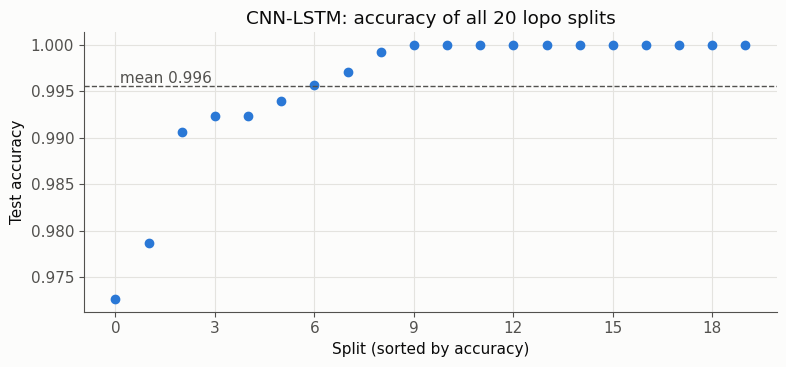

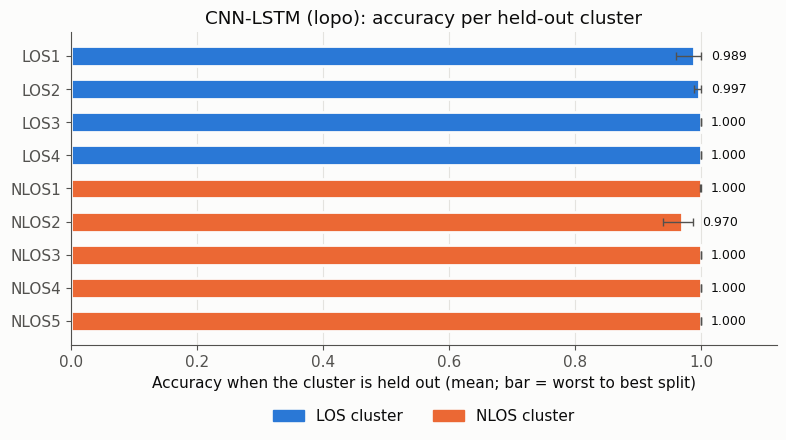

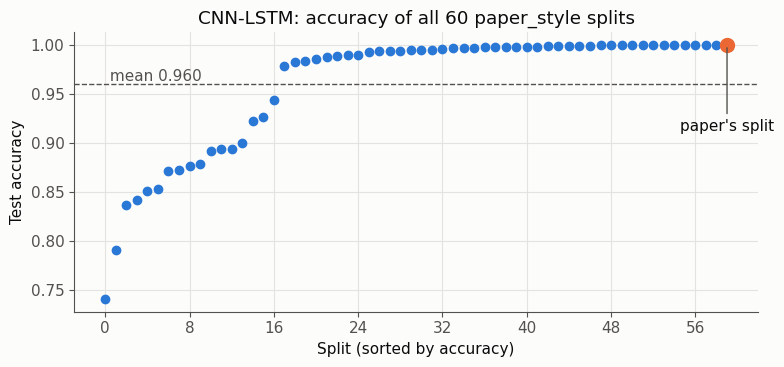

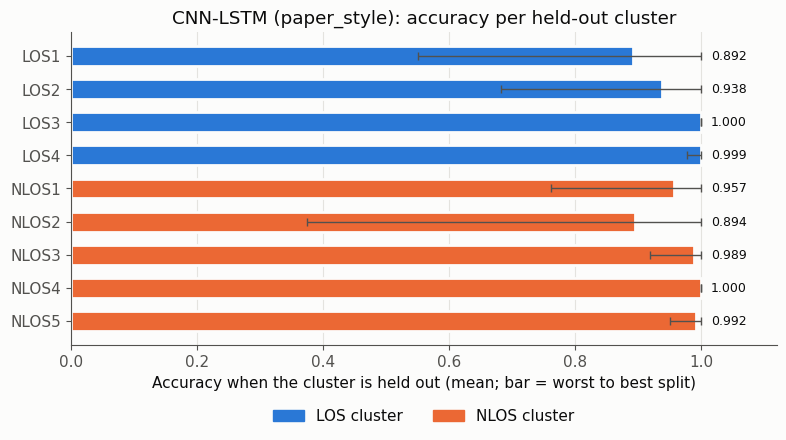

saved: results/splits_summary.json


In [18]:
for protocol, res in ALL_RESULTS.items():
    acc_s = np.array([r["accuracy"] for r in res])
    order = np.argsort(acc_s)
    is_paper = np.array([sorted(r["test"]) == sorted(PAPER_TEST) for r in res])[order]
    fig, ax = plt.subplots(figsize=(8, 3.8))
    ax.plot(np.arange(len(acc_s)), acc_s[order], "o", color=COLOR_LOS, markersize=6)
    if is_paper.any():
        k = int(np.where(is_paper)[0][0])
        ax.plot(k, acc_s[order][k], "o", color=COLOR_NLOS, markersize=10)
        ax.annotate("paper's split", (k, acc_s[order][k]), xytext=(0, -62), textcoords="offset points",
                    ha="center", color=INK, arrowprops={"arrowstyle": "-", "color": INK_2})
    ax.axhline(acc_s.mean(), color=INK_2, linestyle="--", linewidth=1)
    ax.text(0, acc_s.mean(), f" mean {acc_s.mean():.3f}", va="bottom", color=INK_2)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.set_xlabel("Split (sorted by accuracy)")
    ax.set_ylabel("Test accuracy")
    ax.set_title(f"CNN-LSTM: accuracy of all {len(acc_s)} {protocol} splits")
    fig.tight_layout()
    fig.savefig(os.path.join(RESULTS_DIR, f"splits_{protocol}_accuracy.png"), dpi=150)
    plt.show()

    held = SUMMARY[protocol]["held_out_cluster_accuracy"]
    shown = [c for c in ALL_CLUSTERS if c in held]
    means = np.array([held[c]["mean"] for c in shown])
    mins = np.array([held[c]["min"] for c in shown])
    maxs = np.array([max(r["per_cluster_accuracy"][c] for r in res if c in r["per_cluster_accuracy"]) for c in shown])
    colors = [COLOR_LOS if c.startswith("LOS") else COLOR_NLOS for c in shown]
    fig, ax = plt.subplots(figsize=(8, 4.6))
    y = np.arange(len(shown))
    ax.set_axisbelow(True)
    ax.grid(axis="y", visible=False)
    ax.barh(y, means, color=colors, height=0.6, edgecolor="#fcfcfb", linewidth=2)
    ax.errorbar(means, y, xerr=[means - mins, maxs - means], fmt="none", ecolor=INK_2, capsize=3, linewidth=1)
    for yi, m, hi in zip(y, means, maxs):
        ax.text(hi + 0.015, yi, f"{m:.3f}", va="center", color=INK, fontsize=9)
    ax.set_yticks(y, [short(c) for c in shown])
    ax.invert_yaxis()
    ax.set_xlim(0, 1.12)
    ax.set_xlabel("Accuracy when the cluster is held out (mean; bar = worst to best split)")
    ax.set_title(f"CNN-LSTM ({protocol}): accuracy per held-out cluster")
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COLOR_LOS), plt.Rectangle((0, 0), 1, 1, color=COLOR_NLOS)],
              labels=["LOS cluster", "NLOS cluster"], frameon=False, ncol=2,
              loc="upper center", bbox_to_anchor=(0.5, -0.16))
    fig.tight_layout()
    fig.savefig(os.path.join(RESULTS_DIR, f"splits_{protocol}_per_cluster.png"), dpi=150)
    plt.show()

with open(os.path.join(RESULTS_DIR, "splits_summary.json"), "w") as f:
    json.dump({"config": CONFIG, "protocols": SUMMARY}, f, indent=2)
print("saved:", os.path.join(RESULTS_DIR, "splits_summary.json"))

## Step 19: Comparison with SVM, RF and the first CNN-LSTM on the same splits

All models use exactly the same 80 splits, so they are compared split by split. SVM and RF classify single frames; the CNN-LSTMs classify 50-frame windows.

In [19]:
for protocol, res in ALL_RESULTS.items():
    mine = {r["name"]: r for r in res}
    table = {"CNN-LSTM": mine}
    for name, d in OTHER_RESULTS.items():
        path = os.path.join(d, f"splits_{protocol}.jsonl")
        if os.path.exists(path):
            table[name] = load_done(path)
    common = [n for n in mine if all(n in t for t in table.values())]
    print(f"=== {protocol}: {len(common)} splits available for {list(table)}")
    for name, t in table.items():
        a = np.array([t[n]["accuracy"] for n in common])
        print(f"  {name:20s} accuracy {a.mean():.4f} ± {a.std():.4f}   min {a.min():.4f}")
    for name in table:
        if name == "CNN-LSTM":
            continue
        d = np.array([mine[n]["accuracy"] - table[name][n]["accuracy"] for n in common])
        print(f"  CNN-LSTM - {name}: {d.mean():+.4f} on average; better on {(d > 0).sum()}, worse on {(d < 0).sum()} splits")
    print(f"  {'held-out cluster':16s}" + "".join(f"{n[:12]:>14s}" for n in table))
    for c in ALL_CLUSTERS:
        vals = []
        for name, t in table.items():
            v = [t[n]["per_cluster_accuracy"][c] for n in common if c in t[n]["per_cluster_accuracy"]]
            vals.append(np.mean(v) if v else float("nan"))
        print(f"  {c:16s}" + "".join(f"{v:14.4f}" for v in vals))
    print()

=== lopo: 20 splits available for ['CNN-LSTM', 'SVM', 'RF', 'CNN-LSTM v1 (3328)']
  CNN-LSTM             accuracy 0.9956 ± 0.0074   min 0.9726
  SVM                  accuracy 0.9086 ± 0.0906   min 0.7509
  RF                   accuracy 0.9432 ± 0.0815   min 0.7814
  CNN-LSTM v1 (3328)   accuracy 0.8794 ± 0.1477   min 0.4846
  CNN-LSTM - SVM: +0.0871 on average; better on 17, worse on 3 splits
  CNN-LSTM - RF: +0.0525 on average; better on 14, worse on 2 splits
  CNN-LSTM - CNN-LSTM v1 (3328): +0.1162 on average; better on 20, worse on 0 splits
  held-out cluster      CNN-LSTM           SVM            RF  CNN-LSTM v1 
  LOS_cluster1            0.9891        0.8908        0.9552        0.9805
  LOS_cluster2            0.9967        0.6720        0.7011        0.5145
  LOS_cluster3            1.0000        1.0000        0.9965        1.0000
  LOS_cluster4            1.0000        0.9979        1.0000        0.9702
  NLOS_cluster1           0.9996        1.0000        1.0000        0.9897


## Notes

- **Report Part B (mean ± std over splits) as the main result.**
- **The inner held-out accuracy** (Step 12, Step 17) is computed from training clusters only. It can be reported as the expected accuracy in new environments without touching the test clusters.
- **Randomness:** neural-network training isn't fully deterministic, even with a fixed seed. Mean ± std over 80 splits is robust to it.
- **Known data artefacts:** the SNR difference (38 vs 19 dB) and the interference spur at subcarriers 12–14 (`../AUDIT.md`) are also present in the 52-value input (subcarriers 12–14 are part of it).
- **First version:** `results_v1_full_resolution/` holds the 3328-input results (84.6% ± 10.5% over 60 splits) for comparison.